# Commons

In [3]:
from __future__ import annotations

from pathlib import Path
import os

import numpy as np
import pandas as pd
import pydicom
import torch
from skimage.transform import resize
from torch.utils.data import DataLoader, Dataset

### Data functions ###


def ct_normalization(img, meta):
    """
    Normaliza el rango HU a [0, 1].
    Ajustamos de -1024 (aire) a 3072 (tejido denso) para cubrir un rango amplio
    para resaltar detalles anatómicos.
    """
    def scale(img, meta, slope=1.0, intersept=-1024):
        MIN_B = -1024
        MAX_B = 3072

        slope = float(meta.get("Rescale Slope", slope))
        intersept = float(meta.get("Rescale Intercept", intersept))
        
        img = np.asarray(img) * slope + intersept  # Aplica la transformación de escala y desplazamiento
        img = resize(img, (256, 256), preserve_range=True)  # Asegura que todas las imágenes tengan el mismo tamaño
        img = (img - MIN_B) / (MAX_B - MIN_B)  # Escala a [0, 1]
        if img.ndim == 2:
            img = np.expand_dims(img, axis=0)
        return img.astype(np.float32)
    
    return scale(img, meta)


def _read_dicom(path: Path) -> np.ndarray:
    
    ds = pydicom.dcmread(path)  # Lee el archivo DICOM y convierte a numpy array
    metadata = {}
    for element in ds:
            if getattr(element, "name", None) == "Pixel Data":
                continue
            try:
                name = str(element.name)
                value = element.value
                if value is None:
                    continue
                metadata[name] = str(value)
            except Exception:
                continue

    return ct_normalization(ds.pixel_array, metadata)

def save_tensor_cache(tensor, cache_path: Path) -> None:
        if cache_path is None:
            return
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        tmp_path = cache_path.with_suffix(cache_path.suffix + ".tmp")
        torch.save(tensor, tmp_path)
        try:
            with open(tmp_path, "rb+") as handle:
                os.fsync(handle.fileno())
        except OSError:
            pass
        os.replace(tmp_path, cache_path)


class LDCTDataset(Dataset):
    def __init__(
        self,
        df: pd.DataFrame,
        dim: int = 2,
        model_type: str = "model",
    ) -> None:
        """
        Args:
            df: DataFrame with either:
                - dim == 2: columns ['Case', 'SDCT', 'LDCT'] where SDCT/LDCT are file paths to DICOM images
                - dim == 3: columns ['Case', 'SDCT', 'LDCT'] where SDCT/LDCT are volume directories
            transform: Optional transform to be applied on a sample.
            model_type: "model" or "vae", used to determine how to process the data.
        """
        self.dim = dim
        self.data = df.dropna()
        self.model_type = model_type
        self.cache_saving = False

        self._preprocess()

    def _preprocess(self) -> pd.DataFrame:
        rows = []

        unwrap_dir = lambda path: sorted([str(path / fname) for fname in os.listdir(path) if (path / fname).is_file()])

        idx = 0
        for row in self.data.itertuples(index=False):
            sdct_dir = Path(row.SDCT)
            sdct_files = unwrap_dir(sdct_dir)
            
            if self.model_type == "model":
                ldct_dir = Path(row.LDCT)
                ldct_files = unwrap_dir(ldct_dir)
                
                if self.dim == 3:
                    rows.append({
                        'Case': row.Case, 
                        'SDCT': sdct_files, 
                        'LDCT': ldct_files,
                        'split_count': len(ldct_files),
                        'split_idx': idx
                    })
                else:
                    rows.extend([
                        {'Case': row.Case, 'SDCT': s, 'LDCT': l, 'split_count': len(ldct_files), 'split_idx': idxS} 
                        for idxS, (s, l) in enumerate(zip(sdct_files, ldct_files))
                    ])
            
            elif self.model_type == "vae":
                if self.dim == 3:
                    rows.append({
                        'Case': row.Case, 
                        'SDCT': sdct_files,
                        'split_count': len(sdct_files),
                        'split_idx': idx
                    })
                else:
                    rows.extend([
                        {'Case': row.Case, 'SDCT': s, 'split_count': len(sdct_files), 'split_idx': idxS} 
                        for idxS, s in enumerate(sdct_files)
                    ])

            idx += 1
                    
        df = pd.DataFrame(rows)
        self.data = df.to_dict("records")
        self.size = len(self.data)
    
    def load_dicom(self, idx: int, modality: str = "SDCT") -> dict:
        row = self.data[idx]
        cache_path = "./cache/tensors"

        check_cache = lambda modality: True if Path(f"./cache/tensors/{self.data[idx]['Case']}_{modality}.pt").exists() else False

        if self.dim == 3:
            if check_cache(modality):
                cache_file = Path(f"./cache/tensors/{self.data[idx]['Case']}_{modality}.pt")
                return torch.load(cache_file)
            volume = np.array([_read_dicom(f) for f in sorted(row[modality])]) # Shape: (D, H, W)
            tensor = torch.as_tensor(volume).float().contiguous()  # Shape: (1, D, H, W)
            
            if self.cache_saving:
                save_tensor_cache(tensor, cache_path=Path(f"{cache_path}/{row['Case']}_{modality}").with_suffix('.pt'))
                
            return tensor
        else:
            if check_cache(modality):
                cache_file = Path(f"./cache/tensors/{self.data[idx]['Case']}_{modality}.pt")
                return torch.load(cache_file)
            img = _read_dicom(Path(row[modality]))
            tensor = torch.as_tensor(img).float().contiguous()  # Shape: (1, H, W)
            if self.cache_saving:
                save_tensor_cache(tensor, Path(f"{cache_path}/{row['split_idx']}_{row['Case']}_{modality}").with_suffix('.pt'))
            return tensor
    
    def __len__(self) -> int:
        return self.size

    def __getitem__(self, idx: int) -> dict:
        row = self.data[idx]
        sample = {'Case': row['Case']}
        sample['split_idx'] = row['split_idx']
        sample['size'] = (256, 256) if self.dim == 2 else (len(row['SDCT']), 256, 256)
        if self.model_type == "model":
            # sample['SDCT'] = row['SDCT']
            sample['SDCT'] = self.load_dicom(idx, modality='SDCT')
            # sample['LDCT'] = row['LDCT']
            sample['LDCT'] = self.load_dicom(idx, modality='LDCT')
        elif self.model_type == "vae":
            # sample['SDCT'] = row['SDCT']
            sample['SDCT'] = self.load_dicom(idx, modality='SDCT')
        
        return sample

In [4]:
import torch.nn.functional as F

## Eval Functions ##

def save_checkpoint(state: dict, path: Path) -> None:
    if torch is None:
        raise RuntimeError("save_checkpoint requires PyTorch to be installed.")
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(state, path)

def focal_loss(logits: torch.Tensor, targets: torch.Tensor, alpha: float = 0.25, gamma: float = 2.0, reduction: str = "mean") -> torch.Tensor:
    """
    Simple focal loss on logits (binary). Defaults follow the original focal paper.
    """
    prob = torch.sigmoid(logits)
    ce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    p_t = prob * targets + (1 - prob) * (1 - targets)
    alpha_t = alpha * targets + (1 - alpha) * (1 - targets)
    loss = alpha_t * (1 - p_t).pow(gamma) * ce
    if reduction == "mean":
        return loss.mean()
    if reduction == "sum":
        return loss.sum()
    return loss

def bce_focal_loss(logits: torch.Tensor, targets: torch.Tensor, alpha: float = 0.25, gamma: float = 2.0, reduction: str = "mean") -> torch.Tensor:
    """
    Combined BCE + focal loss on logits. No extra weighting; simple sum.
    """
    bce = F.binary_cross_entropy_with_logits(logits, targets, reduction=reduction)
    foc = focal_loss(logits, targets, alpha=alpha, gamma=gamma, reduction=reduction)
    return bce + foc

In [5]:
import os
device = torch.device("cuda:2" if torch.cuda.is_available() else "cpu")

# Test

In [6]:
train = False
val_dataset = pd.read_csv(os.path.join("Dataset", 'train.txt' if train else 'test.txt'), sep='\t', names=('Case','SDCT','LDCT',))
print("Dataset loaded successfully.")
val_ldct_dataset = LDCTDataset(val_dataset, dim=2, model_type="model")
print("Dataset object created successfully.")

Dataset loaded successfully.
Dataset object created successfully.


In [7]:
val_loader = DataLoader(val_ldct_dataset, batch_size=1, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())

Selected Case: C067, Split Index: 249


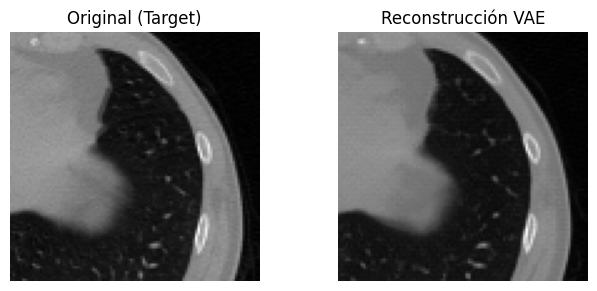

PSNR: 39.13 dB, SSIM: 0.9495


In [10]:
import matplotlib.pyplot as plt
import torch
from monai.networks.nets import AutoencoderKL

# Cargar modelo desde el checkpoints/
torch.cuda.empty_cache()
state_dict = torch.load("./checkpoints/VaeMonai/test_monai_10/monai_100.pt", map_location=device)
# --- 1. Configuración de Hardware y Modelo ---

model = AutoencoderKL(
    spatial_dims=2,
    in_channels=1,
    out_channels=1,
    channels=(128, 256, 512, 512),
    # channels=(64, 128, 256, 512),
    latent_channels=4, 
    num_res_blocks=2,
    attention_levels=(False, False, True, True), 
).to(device)

epoch = 1
num_epochs = 100
model.load_state_dict(state_dict["model"])
model.eval()

import random
from random import randint

# set seed
random.seed(40)

with torch.no_grad():
    batch = val_ldct_dataset.__getitem__(randint(0, len(val_ldct_dataset)-1))
    inputs = batch["SDCT"].to(device)
    print(f"Selected Case: {batch['Case']}, Split Index: {batch['split_idx']}")
    if inputs.ndim == 3:
        inputs = inputs.unsqueeze(1)

    # --- 4. Inferencia ---
    mu, sigma = model.encode(inputs)
    recon = model.decode(mu)

recon = torch.sigmoid(recon)
# --- 5. Visualización de resultados ---
plt.figure(figsize=(10, 3))

# crop = (slice(50, 100), slice(140, 190))
crop = (slice(60, 160), slice(140, 240))
# crop = (slice(0, 256), slice(0, 256))

# Imagen Original (Normal Dose CT / SDCT)
plt.subplot(1, 3, 1)
plt.title("Original (Target)")
# Usamos .detach() por seguridad antes de .cpu()
plt.imshow(inputs[0, 0].detach().cpu()[crop], cmap="gray")
plt.axis("off")

# # Subplot 2: El latente real con ruido (Z)
# plt.subplot(1, 4, 2)
# plt.title("Latente (mu)")
# plt.imshow(np.mean(mu[0].detach().cpu().numpy(), axis=0), cmap="magma")

# Reconstrucción VAE
plt.subplot(1, 3, 2)
plt.title("Reconstrucción VAE") 
plt.imshow(recon[0, 0].detach().cpu()[crop], cmap="gray")
plt.axis("off")

# # Mapa de error
# plt.subplot(1, 3, 3)
# plt.title("Mapa de Error")
# plt.imshow(np.abs(inputs[0, 0].detach().cpu() - recon[0, 0].detach().cpu())[crop], cmap="hot")
# plt.axis("off")


plt.tight_layout()
plt.show()

# PSNR y SSIM
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

# --- CÁLCULO DE MÉTRICAS ---
# Como usaste sigmoid, asumimos que el rango dinámico de tus imágenes es 1.0 (de 0 a 1)
data_range = 1.0 

psnr_val = compute_psnr(inputs[0, 0].detach().cpu().numpy(), recon[0, 0].detach().cpu().numpy(), data_range=data_range)
ssim_val = compute_ssim(inputs[0, 0].detach().cpu().numpy(), recon[0, 0].detach().cpu().numpy(), data_range=data_range)

print(f"PSNR: {psnr_val:.2f} dB, SSIM: {ssim_val:.4f}")

In [ ]:
# psnr_values_model = []
# ssim_values_model = []

# for batch in val_loader:   
#     inputs = batch["SDCT"].to(device)
#     if inputs.ndim == 3:
#         inputs = inputs.unsqueeze(1)

#     # --- 4. Inferencia ---
#     mu, sigma = model.encode(inputs)
#     recon = model.decode(mu)
#     recon = torch.sigmoid(recon)

#     psnr = compute_psnr(inputs[0, 0].detach().cpu().numpy(), recon[0, 0].detach().cpu().numpy(), data_range=data_range)
#     ssim = compute_ssim(inputs[0, 0].detach().cpu().numpy(), recon[0, 0].detach().cpu().numpy(), data_range=data_range)
    
#     psnr_values_model.append(psnr)
#     ssim_values_model.append(ssim)

# mean_psnr = np.mean(psnr_values_model)
# std_psnr = np.std(psnr_values_model, ddof=1)  # desviación estándar muestral

# mean_ssim = np.mean(ssim_values_model)
# std_ssim = np.std(ssim_values_model, ddof=1)

# print(f"PSNR: {mean_psnr:.3f} ± {std_psnr:.3f}")
# print(f"SSIM: {mean_ssim:.4f} ± {std_ssim:.4f}")

# Test CLRM

In [ ]:
path_texts = [os.path.join("Dataset", "clrm_test.txt"), os.path.join("Dataset", "mgc_test.txt")]
clrm_dataset=pd.read_csv(path_texts[0], sep='\t', names=('Case','SDCT','LDCT',))
mgc_dataset=pd.read_csv(path_texts[1], sep='\t', names=('Case','SDCT','LDCT',))

val_clrm_dataset = LDCTDataset(clrm_dataset, model_type="model")
val_mgc_dataset = LDCTDataset(mgc_dataset, model_type="model")

val_clrm_loader = DataLoader(val_clrm_dataset, batch_size=1, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())
val_mgc_loader = DataLoader(val_mgc_dataset, batch_size=1, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())

In [ ]:
from random import randint
import random

random.seed(40)

data_item = val_clrm_dataset.__getitem__(randint(0, len(val_clrm_dataset)-1))
data_item["LDCT"] = data_item["LDCT"].unsqueeze(0)
data_item["SDCT"] = data_item["SDCT"].unsqueeze(0)
print(f"Selected Case: {data_item['Case']}, Split Index: {data_item['split_idx']}")

Selected Case: CRLM-CT-1144, Split Index: 20


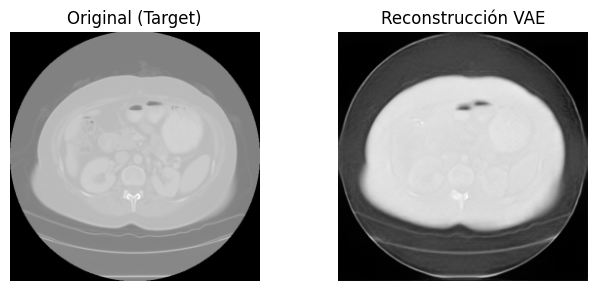

PSNR: 12.77 dB, SSIM: 0.5025


In [ ]:
import matplotlib.pyplot as plt
import torch
from monai.networks.nets import AutoencoderKL
from skimage import exposure


def equalize_images_to_common_contrast(image, reference):
    image = np.asarray(image, dtype=np.float32)
    reference = np.asarray(reference, dtype=np.float32)

    if image.ndim == 2:
        target = exposure.equalize_adapthist(reference)
        image_eq = exposure.match_histograms(image, target)
        reference_eq = exposure.match_histograms(reference, target)

    return np.clip(image_eq, 0.0, 1.0), np.clip(reference_eq, 0.0, 1.0)

model = AutoencoderKL(
    spatial_dims=2,
    in_channels=1,
    out_channels=1,
    channels=(128, 256, 512, 512),
    # channels=(64, 128, 256, 512),
    latent_channels=4, 
    num_res_blocks=2,
    attention_levels=(False, False, True, True), 
).to(device)

# Cargar modelo desde el checkpoints/
torch.cuda.empty_cache()
state_dict = torch.load("./checkpoints/VaeMonai/monai_7/vae_best.pt", map_location=device)
# --- 1. Configuración de Hardware y Modelo ---


model.load_state_dict(state_dict["model"])
model.eval()

with torch.no_grad():
    batch = data_item
    inputs = batch["SDCT"].to(device)
    if inputs.ndim == 3:
        inputs = inputs.unsqueeze(1)

    # --- 4. Inferencia ---
    mu, sigma = model.encode(inputs)
    recon = model.decode(mu)

recon = torch.sigmoid(recon)

recon, inputs = recon[0, 0].detach().cpu().numpy(), inputs[0, 0].detach().cpu().numpy()
# recon, inputs = equalize_images_to_common_contrast(recon, inputs)

plt.figure(figsize=(10, 3))

# crop = (slice(50, 100), slice(140, 190))
# crop = (slice(60, 160), slice(140, 240))
crop = (slice(0, 256), slice(0, 256))

# Imagen Original (Normal Dose CT / SDCT)
plt.subplot(1, 3, 1)
plt.title("Original (Target)")
# Usamos .detach() por seguridad antes de .cpu()
plt.imshow(inputs[crop], cmap="gray")
plt.axis("off")

# # Subplot 2: El latente real con ruido (Z)
# plt.subplot(1, 4, 2)
# plt.title("Latente (mu)")
# plt.imshow(np.mean(mu[0].detach().cpu().numpy(), axis=0), cmap="magma")

# Reconstrucción VAE
plt.subplot(1, 3, 2)
plt.title("Reconstrucción VAE") 
plt.imshow(recon[crop], cmap="gray")
plt.axis("off")

# # --- 5. Visualización de resultados ---
# plt.figure(figsize=(15, 5))

# # Imagen Original (Normal Dose CT / SDCT)
# plt.subplot(1, 4, 1)
# plt.title("Original (Target)")
# # Usamos .detach() por seguridad antes de .cpu()
# plt.imshow(inputs[0, 0].detach().cpu(), cmap="gray")
# plt.axis("off")
# # Subplot 2: El latente real con ruido (Z)
# plt.subplot(1, 4, 2)
# plt.title("Latente (mu)")
# plt.imshow(np.mean(mu[0].detach().cpu().numpy(), axis=0), cmap="magma")

# # Reconstrucción VAE
# plt.subplot(1, 4, 3)
# plt.title("Reconstrucción VAE") 
# plt.imshow(recon[0, 0].detach().cpu(), cmap="gray")
# plt.axis("off")

# # Mapa de error
# plt.subplot(1, 4, 4)
# plt.title("Mapa de Error")
# plt.imshow(np.abs(inputs[0, 0].detach().cpu() - recon[0, 0].detach().cpu()), cmap="hot")
# plt.axis("off")

plt.tight_layout()
plt.show()

# PSNR y SSIM
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

# --- CÁLCULO DE MÉTRICAS ---
# Como usaste sigmoid, asumimos que el rango dinámico de tus imágenes es 1.0 (de 0 a 1)
data_range = 1.0 

psnr_val = compute_psnr(inputs, recon, data_range=data_range)
ssim_val = compute_ssim(inputs, recon, data_range=data_range)

print(f"PSNR: {psnr_val:.2f} dB, SSIM: {ssim_val:.4f}")

In [ ]:
train = False
val_dataset = pd.read_csv(os.path.join("Dataset", 'train.txt' if train else 'test.txt'), sep='\t', names=('Case','SDCT','LDCT',))
val_ldct_dataset = LDCTDataset(val_dataset, dim=2, model_type="model")
val_loader = DataLoader(val_ldct_dataset, batch_size=1, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())
path_texts = [os.path.join("Dataset", "clrm_test.txt"), os.path.join("Dataset", "mgc_test.txt")]
clrm_dataset=pd.read_csv(path_texts[0], sep='\t', names=('Case','SDCT','LDCT',))
mgc_dataset=pd.read_csv(path_texts[1], sep='\t', names=('Case','SDCT','LDCT',))

# clrm_dataset = clrm_dataset.dropna(subset=["SDCT"])
#         # Select random 50% to train and 50% to validation
# train_indices = clrm_dataset.sample(frac=0.5, random_state=42).index
# val_indices = clrm_dataset.drop(train_indices).index
# val_clrm_dataset = LDCTDataset(clrm_dataset.iloc[val_indices], model_type="model")

val_clrm_dataset = LDCTDataset(clrm_dataset, model_type="model")
val_mgc_dataset = LDCTDataset(mgc_dataset, model_type="model")

val_clrm_loader = DataLoader(val_clrm_dataset, batch_size=1, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())
val_mgc_loader = DataLoader(val_mgc_dataset, batch_size=1, shuffle=True, num_workers=4, pin_memory=torch.cuda.is_available())

In [ ]:
datasets = [val_loader, val_mgc_loader, val_clrm_loader]
index = 0
name = ["TCIA", "MGC", "CLRM"]

for loader in datasets:
    psnr_values_model = []
    ssim_values_model = []
    for batch in loader:   
        inputs = batch["SDCT"].to(device)
        if inputs.ndim == 3:
            inputs = inputs.unsqueeze(1)

        # --- 4. Inferencia ---
        mu, sigma = model.encode(inputs)
        recon = model.decode(mu)
        recon = torch.sigmoid(recon)

        recon, inputs = recon[0, 0].detach().cpu().numpy(), inputs[0, 0].detach().cpu().numpy()

        if name[index] == "CLRM":
            recon, inputs = equalize_images_to_common_contrast(recon, inputs)

        psnr = compute_psnr(inputs, recon, data_range=data_range)
        ssim = compute_ssim(inputs, recon, data_range=data_range)
        
        psnr_values_model.append(psnr)
        ssim_values_model.append(ssim)

    mean_psnr = np.mean(psnr_values_model)
    std_psnr = np.std(psnr_values_model, ddof=1)  # desviación estándar muestral

    mean_ssim = np.mean(ssim_values_model)
    std_ssim = np.std(ssim_values_model, ddof=1)

    print(f"PSNR: {mean_psnr:.3f} ± {std_psnr:.3f}")
    print(f"SSIM: {mean_ssim:.4f} ± {std_ssim:.4f}")
    index += 1

PSNR: 42.256 ± 3.873
SSIM: 0.9688 ± 0.0243
PSNR: 41.815 ± 2.846
SSIM: 0.9676 ± 0.0132
PSNR: 22.155 ± 2.033
SSIM: 0.6024 ± 0.0695
